<a href="https://colab.research.google.com/github/hilduAgl/brain-age-eeg/blob/main/evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Brain Age Prediction — Model Evaluation

This notebook evaluates models for predicting chronological age
from EEG recordings.

## Models
- Ridge regression using handcrafted EEG features.
- CNN using one 8-second EEG window.
- CNN using predictions averaged across 20 evenly spaced
  8-second windows.

## Evaluation
1. Validation-set comparison (103 subjects).
2. Prediction error and age-group analysis.
3. Final test-set comparison (104 subjects).

The CNN inference configuration was selected using validation MAE.
The held-out test set is used for final performance evaluation.

In [2]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

RESULTS_DIR = Path("/content/drive/MyDrive/BrainAge/results")
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Results directory:", RESULTS_DIR)
print("\nAvailable prediction files:")

for path in sorted(RESULTS_DIR.glob("*.csv")):
    print(path.name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Results directory: /content/drive/MyDrive/BrainAge/results

Available prediction files:
Afrit af cnn_val_predictions.csv
baseline_test_predictions.csv
baseline_val_predictions.csv
cnn_flat_8s_10windows_val_predictions.csv
cnn_flat_8s_1window_val_predictions.csv
cnn_flat_8s_1windows_val_predictions.csv
cnn_flat_8s_20windows_val_predictions.csv
cnn_flat_8s_5windows_val_predictions.csv
cnn_val_predictions (Betra model).csv
cnn_val_predictions.csv
cnn_val_predictions3.csv


## Load Model Predictions

In [3]:
MODEL_FILES = {
    "Ridge regression": "baseline_val_predictions.csv",
    "CNN (1 window)": "cnn_flat_8s_1windows_val_predictions.csv",
    "CNN (20 windows)": "cnn_flat_8s_20windows_val_predictions.csv",
}

predictions = {}

for model_name, filename in MODEL_FILES.items():
    path = RESULTS_DIR / filename

    if not path.exists():
        print(f"Missing: {filename}")
        continue

    df = pd.read_csv(path)

    required = {"filename", "actual_age", "predicted_age"}
    assert required.issubset(df.columns), (
        f"{model_name}: Missing required columns"
    )

    assert df["filename"].is_unique, (
        f"{model_name}: Duplicate subjects"
    )

    predictions[model_name] = df

    print(f"{model_name}: {len(df)} subjects loaded")

Ridge regression: 103 subjects loaded
CNN (1 window): 103 subjects loaded
CNN (20 windows): 103 subjects loaded



## Verify subject alignment

Before comparing models, we check that all prediction files
contain the same subjects and that their actual ages agree.

This ensures that differences in evaluation metrics are
caused by model predictions rather than differences in
which children were evaluated.


In [5]:
assert len(predictions) == len(MODEL_FILES), (
    "Not all prediction files were found"
)

reference = predictions["CNN (1 window)"]

reference_ages = reference.set_index("filename")["actual_age"]

for name, df in predictions.items():
    current = df.set_index("filename")

    assert set(current.index) == set(reference_ages.index), (
        f"{name}: Subject sets do not match"
    )

    np.testing.assert_allclose(
        current.loc[reference_ages.index, "actual_age"],
        reference_ages.values,
        rtol=0,
        atol=1e-5
    )

print("All models evaluated on the same subjects")

All models evaluated on the same subjects



## Evaluation Metrics

All metrics are calculated at the subject level, with one
predicted age per child.

- MAE: The average absolute difference between predicted
  and actual age, measured in years.
- RMSE: Similar to MAE, but gives greater weight to large
  prediction errors.
- Bias: The average signed prediction error.

Positive bias indicates overestimation of age, while
negative bias indicates underestimation.

Lower MAE and RMSE indicate better predictive accuracy.
A bias closer to zero indicates less systematic
overestimation or underestimation.


In [6]:
rows = []

for name, df in predictions.items():
    actual = df["actual_age"].to_numpy()
    predicted = df["predicted_age"].to_numpy()

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    bias = np.mean(predicted - actual)

    rows.append({
        "Model": name,
        "MAE (years)": mae,
        "RMSE (years)": rmse,
        "Bias (years)": bias,
    })

metrics_df = pd.DataFrame(rows)
metrics_df = metrics_df.sort_values("MAE (years)")

display(metrics_df.round(4))

,Model,MAE (years),RMSE (years),Bias (years)
0,Ridge regression,1.1346,1.4206,0.2279
2,CNN (20 windows),1.2507,1.6724,0.3296
1,CNN (1 window),1.4846,2.1213,0.7412


Compare models visually

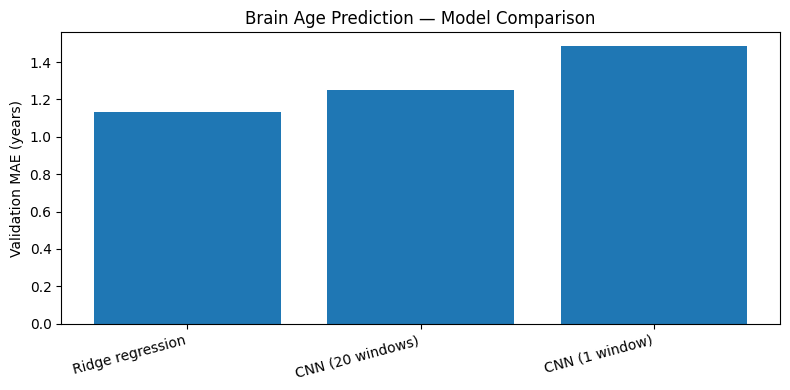

In [7]:
plt.figure(figsize=(8, 4))

plt.bar(
    metrics_df["Model"],
    metrics_df["MAE (years)"]
)

plt.ylabel("Validation MAE (years)")
plt.title("Brain Age Prediction — Model Comparison")
plt.xticks(rotation=15, ha="right")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "model_comparison_mae.png",
    dpi=200
)
plt.show()

Actual age vs predicted age

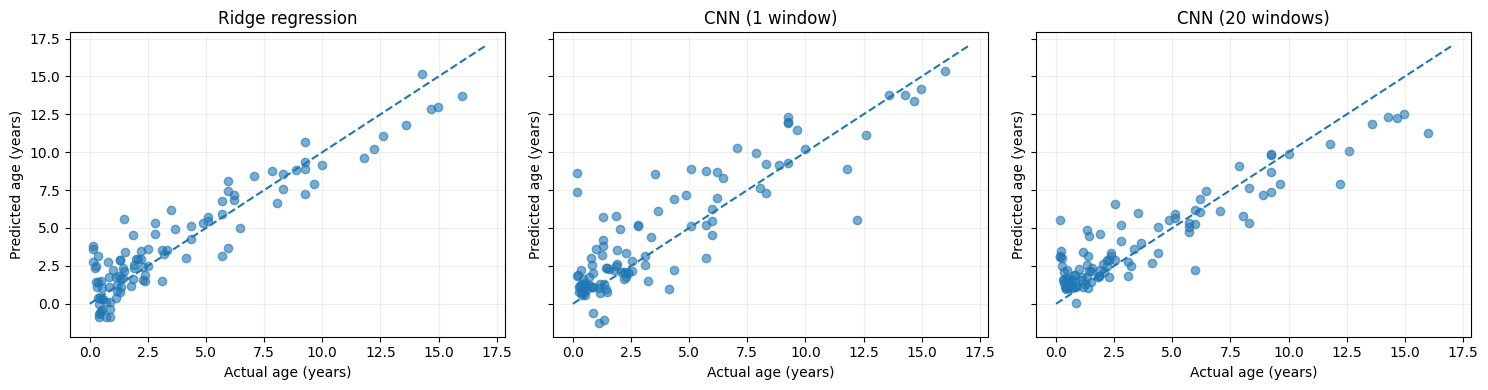

In [8]:
fig, axes = plt.subplots(
    1, len(predictions),
    figsize=(5 * len(predictions), 4),
    sharex=True,
    sharey=True
)

for ax, (name, df) in zip(axes, predictions.items()):
    ax.scatter(
        df["actual_age"],
        df["predicted_age"],
        alpha=0.6
    )

    ax.plot([0, 17], [0, 17], linestyle="--")

    ax.set_title(name)
    ax.set_xlabel("Actual age (years)")
    ax.set_ylabel("Predicted age (years)")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "actual_vs_predicted.png",
    dpi=200
)
plt.show()

Prediction error vs actual age

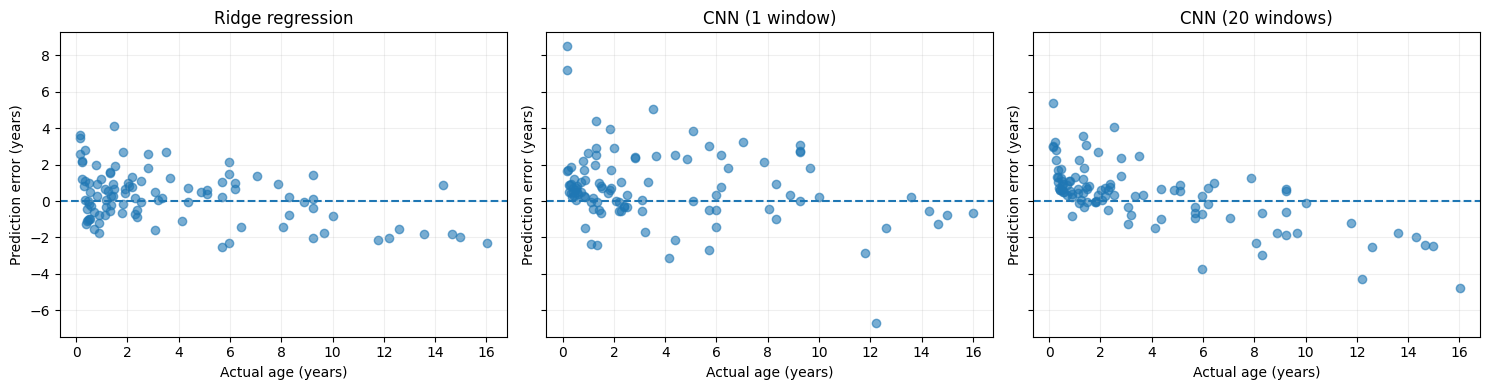

In [9]:
fig, axes = plt.subplots(
    1, len(predictions),
    figsize=(5 * len(predictions), 4),
    sharex=True,
    sharey=True
)

for ax, (name, df) in zip(axes, predictions.items()):
    error = df["predicted_age"] - df["actual_age"]

    ax.scatter(
        df["actual_age"],
        error,
        alpha=0.6
    )

    ax.axhline(0, linestyle="--")

    ax.set_title(name)
    ax.set_xlabel("Actual age (years)")
    ax.set_ylabel("Prediction error (years)")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "error_vs_age.png",
    dpi=200
)
plt.show()


## Evaluation Metrics

All metrics are calculated at the subject level, with one
predicted age per child.

- MAE: The average absolute difference between predicted
  and actual age, measured in years.
- RMSE: Similar to MAE, but gives greater weight to large
  prediction errors.
- Bias: The average signed prediction error.

Positive bias indicates overestimation of age, while
negative bias indicates underestimation.

Lower MAE and RMSE indicate better predictive accuracy.
A bias closer to zero indicates less systematic
overestimation or underestimation.


In [10]:
AGE_BINS = [0, 2, 5, 10, np.inf]
AGE_LABELS = ["0–2", "2–5", "5–10", "10+"]

age_results = []

for name, df in predictions.items():
    temp = df.copy()

    temp["age_group"] = pd.cut(
        temp["actual_age"],
        bins=AGE_BINS,
        labels=AGE_LABELS,
        right=False
    )

    temp["absolute_error"] = (
        temp["predicted_age"] - temp["actual_age"]
    ).abs()

    grouped = temp.groupby(
        "age_group",
        observed=False
    )["absolute_error"].agg(["mean", "count"])

    for group, row in grouped.iterrows():
        age_results.append({
            "Model": name,
            "Age group": group,
            "MAE": row["mean"],
            "Subjects": int(row["count"])
        })

age_df = pd.DataFrame(age_results)

display(age_df.round(4))

,Model,Age group,MAE,Subjects
0,Ridge regression,0–2,1.1415,50
1,Ridge regression,2–5,0.9186,22
2,Ridge regression,5–10,1.1037,22
3,Ridge regression,10+,1.7003,9
4,CNN (1 window),0–2,1.4056,50
5,CNN (1 window),2–5,1.4636,22
6,CNN (1 window),5–10,1.6224,22
7,CNN (1 window),10+,1.6376,9
8,CNN (20 windows),0–2,1.2072,50
9,CNN (20 windows),2–5,0.9921,22


Visualize:

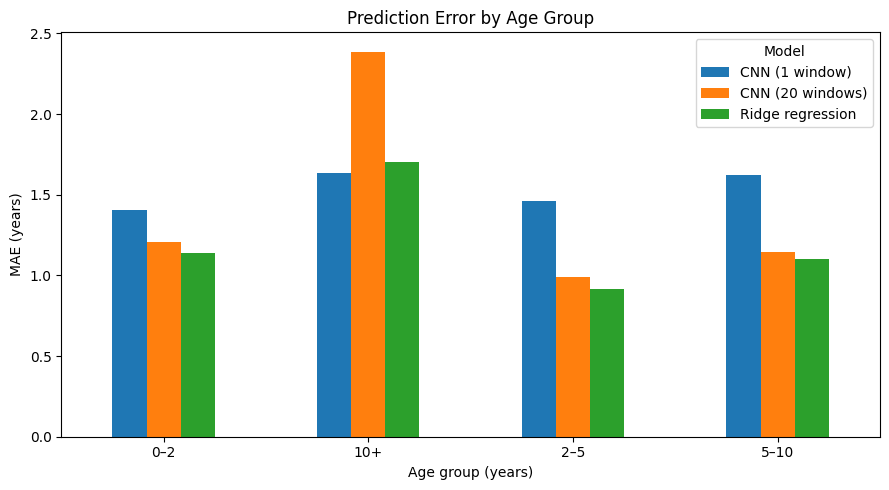

In [11]:
pivot = age_df.pivot(
    index="Age group",
    columns="Model",
    values="MAE"
)

pivot.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.ylabel("MAE (years)")
plt.xlabel("Age group (years)")
plt.title("Prediction Error by Age Group")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "mae_by_age_group.png",
    dpi=200
)
plt.show()

Save comparison tables

In [12]:
metrics_df.to_csv(
    RESULTS_DIR / "validation_model_comparison.csv",
    index=False
)

age_df.to_csv(
    RESULTS_DIR / "validation_age_group_errors.csv",
    index=False
)

print("Evaluation results saved")

Evaluation results saved


## Final Test-Set Evaluation

The final models and inference configurations were selected using
validation results.

This section compares the selected Ridge regression model and
20-window CNN on the held-out test subjects.

In [13]:
TEST_MODEL_FILES = {
    "Ridge regression": "baseline_test_predictions.csv",
    "CNN (20 windows)": "cnn_flat_8s_20windows_test_predictions.csv",
}

test_predictions = {}

for name, filename in TEST_MODEL_FILES.items():
    df = pd.read_csv(RESULTS_DIR / filename)

    assert len(df) == 104
    assert df["filename"].is_unique
    assert df[["actual_age", "predicted_age"]].notna().all().all()

    test_predictions[name] = df

# Check that both models evaluated the same children
ridge = test_predictions["Ridge regression"].set_index("filename")
cnn = test_predictions["CNN (20 windows)"].set_index("filename")

assert set(ridge.index) == set(cnn.index)

np.testing.assert_allclose(
    ridge.loc[cnn.index, "actual_age"],
    cnn["actual_age"],
    atol=1e-5,
    rtol=0
)

# Calculate test metrics
test_results = []

for name, df in test_predictions.items():
    actual = df["actual_age"].to_numpy()
    predicted = df["predicted_age"].to_numpy()

    test_results.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "Bias": np.mean(predicted - actual),
    })

test_metrics_df = pd.DataFrame(test_results)
display(test_metrics_df.round(4))

test_metrics_df.to_csv(
    RESULTS_DIR / "final_test_comparison.csv",
    index=False
)

,Model,MAE,RMSE,Bias
0,Ridge regression,1.1251,1.4647,0.0378
1,CNN (20 windows),1.0214,1.3416,0.2090


Final predicted vs actual plot

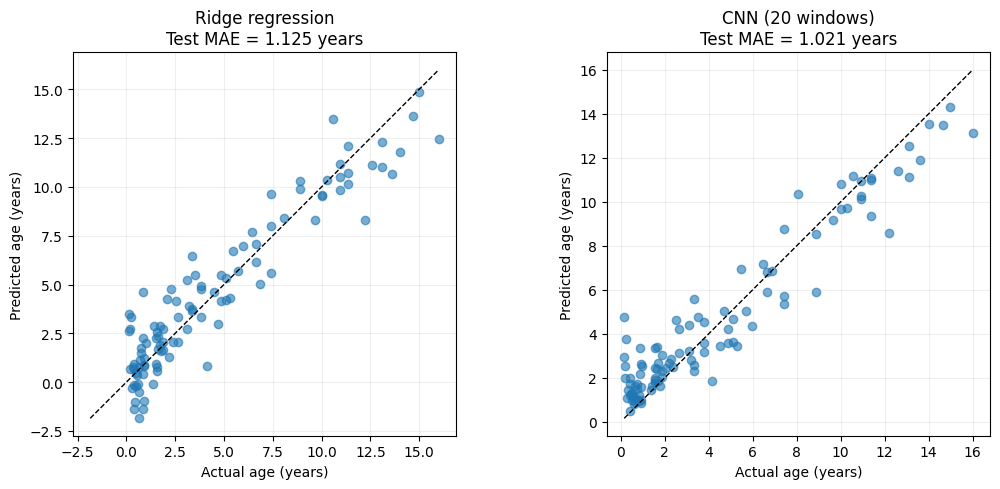

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, (name, df) in zip(axes, test_predictions.items()):
    actual = df["actual_age"]
    predicted = df["predicted_age"]

    ax.scatter(actual, predicted, alpha=0.6)

    low = min(actual.min(), predicted.min())
    high = max(actual.max(), predicted.max())

    ax.plot(
        [low, high],
        [low, high],
        "k--",
        linewidth=1
    )

    mae = mean_absolute_error(actual, predicted)

    ax.set_title(f"{name}\nTest MAE = {mae:.3f} years")
    ax.set_xlabel("Actual age (years)")
    ax.set_ylabel("Predicted age (years)")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "final_test_predictions.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()